# Epistemic vs aleatoric uncertainty -> pathway enrichment, on the three cohorts

Per-gene epistemic and aleatoric uncertainty, aggregated slide-aware (within-slide z-score across
genes, then the median over slides), de-confounded from expression by a loess fit, then tested for
Hallmark over-representation (hypergeometric ORA) on the top and bottom 100 genes against the
panel background. The cohort is a key throughout.

**Runs.** Deep ensemble from the `de_6` run; MC-dropout and Laplace from `pr_classic1`. The
single-model `pr_classic3` runs are NOT needed: each `test_summaries.h5ad` carries `layers['y']`,
so the per-gene predictability of section 5 is computed from the same file.

**Three choices worth flagging.**
1. **The background is per cohort.** The three cohorts have three different 3000-gene panels, so
   a single shared background would test each cohort against another cohort's gene universe.
2. **Matrices are reduced to per-gene vectors inside the load loop and then freed.** Holding every
   (cohort, model, method) source of (77k x 3000) in float64 at once would need tens of gigabytes;
   only the peak memory differs, not the numbers.
3. **A diagnostic on the de-confound**: the Spearman of the loess-adjusted score against
   expression. It decides whether an `ADJ` enrichment is de-confounded or still riding the
   expression ranking, and is marked `ADDED` in the column names wherever it appears.

## 0. Config + generalized loader

In [1]:
import sys, gc
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import spearmanr, hypergeom
from skmisc.loess import loess

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(PROJ))

DATASETS = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
RADIUS   = 'r75'
GMT      = 'data/pathways/msigdb_hallmark_2020.gmt'   # MSigDB Hallmark 2020, downloaded separately

# Which (run directory, run_id, post-hoc subdir) holds each epistemic method. The deep ensemble
# is its own run; MC-dropout and Laplace are post-hoc siblings written next to the training run.
METHOD_SOURCES = [('ensemble',   'de_6',        'de_6'),
                  ('mc_dropout', 'pr_classic1', 'pr_classic1'),
                  ('laplace',    'pr_classic1', 'pr_classic1')]

# Only *_cp count heads are valid: the raw-count models ('poisson',
# 'negativebinomial_hetero_noanchor') score against the true per-spot size factor, an oracle
# covariate, so they are excluded here by standing decision. Drop to ['heteroscedastic'] for
# a faster first pass.
MODELS = ['heteroscedastic', 'negativebinomial_hetero_noanchor_cp', 'poisson_cp']
SHORT  = {'heteroscedastic': 'gauss_het',
          'negativebinomial_hetero_noanchor_cp': 'NB_hetero_cp', 'poisson_cp': 'poisson_cp'}


def summary_paths(ds):
    '''Every (model, method) test_summaries.h5ad present for this cohort, found by search.

    The Gaussian heads sit under a lambda_ level in some run_ids and not others (the ensemble drops
    it, lambda being constant across members), so a hard-coded leaf breaks on one arm or the other.
    lambda_0.0 is the proper NLL and is preferred when several exist.
    '''
    found = {}
    for method, snap, rid in METHOD_SOURCES:
        base = PROJ / 'results' / ds / rid / f'_{ds}_hvg_top3000' / RADIUS
        if not base.is_dir():
            continue
        for model in MODELS:
            hits = [p for p in base.rglob('test_summaries.h5ad')
                    if p.parent.name == method and f'/{model}/' in str(p).replace('\\', '/')]
            if hits:
                hits.sort(key=lambda p: ('lambda_0.0' not in str(p), str(p)))
                found[(model, method)] = hits[0]
    return found


print('WHAT IS ON DISK (this is the answer to "do we have the runs")')
AVAIL = {}
for ds in DATASETS:
    AVAIL[ds] = summary_paths(ds)
    got = sorted(f'{SHORT.get(m, m)}|{me}' for m, me in AVAIL[ds])
    print(f'  {ds:12s} {len(got)} source(s): {got if got else "NONE FOUND"}')
print('\nA missing (model, method) is skipped everywhere below, never faked.')


def load_summary(path):
    '''Read one test_summaries.h5ad. Matrices are stored float32; the reductions stay float64.'''
    a = sc.read_h5ad(path)
    info = dict(next((a.uns[k] for k in ('deep_ensemble', 'mc_dropout', 'laplace') if k in a.uns), {}))
    # convention guard: mc_dropout, laplace AND deep_ensemble_combine all stamp this marker. An
    # unmarked file carries a mean relative to a per-spot size factor and is refused outright:
    # re-run the precompute rather than reading it.
    assert a.uns.get('count_convention') == 'v2_no_offset', \
        f'unmarked artifact: {path}. Re-run the precompute.'
    is_count = bool(info.get('count', False))
    mean_pred = np.asarray(a.X, dtype=np.float32)
    epistemic = np.asarray(a.layers['epistemic'], dtype=np.float32)
    y_raw = np.asarray(a.layers['y'], dtype=np.float32)
    if is_count:
        ds_ = a.uns.get('depth_scale', info.get('depth_scale'))   # None for the depth-blind *_raw family
        div = 1.0 if ds_ is None else float(ds_)                  # divisor, ONLY on the log1p axis
        extra = (np.asarray(a.layers['mean_alpha_m2'], dtype=np.float32)
                 if 'mean_alpha_m2' in a.layers else np.float32(0.0))
        aleatoric = mean_pred + extra                             # target scale (Poisson: == mean)
        mean_log = np.log1p(mean_pred / div)
        y_log = np.log1p(y_raw / div)
    else:
        aleatoric = np.asarray(a.layers['aleatoric_var'], dtype=np.float32)   # log1p-CP10k native
        mean_log, y_log = mean_pred, y_raw
    return dict(is_count=is_count, scale=info.get('mean_scale', '?'),
                epistemic=epistemic, aleatoric=aleatoric, mean_log=mean_log, y_log=y_log,
                slide=a.obs['slide'].to_numpy().astype(str),
                genes=np.asarray(a.var_names).astype(str))

WHAT IS ON DISK (this is the answer to "do we have the runs")
  10x_TuPro    9 source(s): ['NB_hetero_cp|ensemble', 'NB_hetero_cp|laplace', 'NB_hetero_cp|mc_dropout', 'gauss_het|ensemble', 'gauss_het|laplace', 'gauss_het|mc_dropout', 'poisson_cp|ensemble', 'poisson_cp|laplace', 'poisson_cp|mc_dropout']
  TLS          9 source(s): ['NB_hetero_cp|ensemble', 'NB_hetero_cp|laplace', 'NB_hetero_cp|mc_dropout', 'gauss_het|ensemble', 'gauss_het|laplace', 'gauss_het|mc_dropout', 'poisson_cp|ensemble', 'poisson_cp|laplace', 'poisson_cp|mc_dropout']
  LUNG_CANCER  9 source(s): ['NB_hetero_cp|ensemble', 'NB_hetero_cp|laplace', 'NB_hetero_cp|mc_dropout', 'gauss_het|ensemble', 'gauss_het|laplace', 'gauss_het|mc_dropout', 'poisson_cp|ensemble', 'poisson_cp|laplace', 'poisson_cp|mc_dropout']

A missing (model, method) is skipped everywhere below, never faked.


## 1. Per-gene score: slide-aware aggregation + expression de-confound

Spots to per-slide mean, optional within-slide z-score **across genes**
(puts every slide on a common scale), then the median over slides (robust to one odd slide). The
confounder is the **predicted** mean on the uncertainty's own native scale (log1p-CP10k for the
Gaussians, CP10k for the count heads), because a loess fitted on the wrong scale cannot capture
that family's mean-variance trend. `epi_frac` is a ratio of positive variances, so it is built from
the RAW aggregates and never from the z-scored ones.

Each source is loaded, reduced to per-gene vectors, and freed before the next one is opened.

In [2]:
def per_gene_score(mat, slide, slides, zscore=True):
    """spots -> per-slide mean; optional within-slide z-score ACROSS GENES (common slide scale);
    then median over slides (robust to an odd slide). Slide-aware."""
    U = np.vstack([np.nanmean(mat[slide == sl], axis=0, dtype=np.float64) for sl in slides])
    if zscore:
        U = (U - np.nanmean(U, axis=1, keepdims=True)) / np.nanstd(U, axis=1, keepdims=True)
    return np.nanmedian(U, axis=0)


def per_gene_pred_corr(mu, y, slide, slides):
    """Slide-aware Pearson(mu, y) per gene: per-slide Pearson over spots, then median over slides."""
    cols = []
    for sl in slides:
        m = slide == sl
        a, b = mu[m].astype(np.float64), y[m].astype(np.float64)
        ac, bc = a - a.mean(0), b - b.mean(0)
        num = (ac * bc).sum(0)
        den = np.sqrt((ac ** 2).sum(0) * (bc ** 2).sum(0))
        with np.errstate(invalid='ignore', divide='ignore'):
            cols.append(np.where(den > 0, num / den, np.nan))
    return np.nanmedian(np.vstack(cols), axis=0)


def per_gene_var(mat, slide, slides):
    """Slide-aware variance of a matrix across spots: per-slide variance, median over slides."""
    return np.nanmedian(np.vstack([np.nanvar(mat[slide == sl], axis=0, dtype=np.float64)
                                   for sl in slides]), axis=0)


def expr_adjust(score, expr, span=0.5, degree=2):
    """loess(score ~ expr); keep the residual (removes the expression trend)."""
    out = np.full(score.shape, np.nan)
    ok = np.isfinite(score) & np.isfinite(expr)
    lo = loess(expr[ok], score[ok], span=span, degree=degree)
    lo.fit()
    out[ok] = score[ok] - lo.outputs.fitted_values
    return out


ZSCORE = True     # z-score the uncertainties within-slide (across genes) before the median
PG = {}
for ds in DATASETS:
    for (model, method), path in sorted(AVAIL[ds].items()):
        d = load_summary(path)
        slide, slides = d['slide'], pd.unique(d['slide'])
        epi = per_gene_score(d['epistemic'], slide, slides, ZSCORE)
        alea = per_gene_score(d['aleatoric'], slide, slides, ZSCORE)
        tot = per_gene_score(d['aleatoric'] + d['epistemic'], slide, slides, ZSCORE)
        # epi-fraction is a RATIO of (positive) variances -> from the RAW aggregates, not z-scores
        epi_raw = per_gene_score(d['epistemic'], slide, slides, zscore=False)
        alea_raw = per_gene_score(d['aleatoric'], slide, slides, zscore=False)
        epi_frac = np.where((epi_raw + alea_raw) > 0, epi_raw / (epi_raw + alea_raw), np.nan)
        # confounder = PREDICTED mean, on the uncertainty's NATIVE scale (the cp10k fix)
        mean_native = np.expm1(d['mean_log']) if d['is_count'] else d['mean_log']
        expr = per_gene_score(mean_native, slide, slides, zscore=False)
        y_native = np.expm1(d['y_log']) if d['is_count'] else d['y_log']
        expr_obs = per_gene_score(y_native, slide, slides, zscore=False)   # for the sensitivity check
        pcorr = per_gene_pred_corr(d['mean_log'], d['y_log'], slide, slides)
        tvar = per_gene_var(d['y_log'], slide, slides)                     # for section 6
        # the no-z-score aggregation, used by the sensitivity check of the next cell
        df = pd.DataFrame(dict(gene=d['genes'], epi=epi, alea=alea, total=tot, epi_frac=epi_frac,
                               epi_nz=epi_raw, alea_nz=alea_raw,
                               gene_mean_expr=expr, gene_obs_expr=expr_obs,
                               pred_corr=pcorr, target_var=tvar))
        for col in ('epi', 'alea', 'total', 'epi_frac'):
            df[col + '_adj'] = expr_adjust(df[col].to_numpy(), df['gene_mean_expr'].to_numpy())
            df[col + '_adjobs'] = expr_adjust(df[col].to_numpy(), df['gene_obs_expr'].to_numpy())
        PG[(ds, model, method)] = df
        print(f"{ds:12s} | {SHORT.get(model, model):13s} | {method:10s} | count: {d['is_count']} "
              f"| scale: {d['scale']:18s} | {d['epistemic'].shape[0]:,} spots x "
              f"{d['epistemic'].shape[1]} genes | slides: {len(slides)}")
        print(f"    rho(epi, expr) = {spearmanr(df['epi'], df['gene_mean_expr'])[0]:+.3f} "
              f"| rho(alea, expr) = {spearmanr(df['alea'], df['gene_mean_expr'])[0]:+.3f} "
              f"| median pred_corr = {float(np.nanmedian(pcorr)):+.3f}")
        del d
        gc.collect()

print('\navailable (dataset, model, method):')
for k in PG:
    print('   ', k)

10x_TuPro    | gauss_het     | ensemble   | count: False | scale: log1p_cp10k        | 77,338 spots x 3000 genes | slides: 18
    rho(epi, expr) = +0.908 | rho(alea, expr) = +0.978 | median pred_corr = +0.137
10x_TuPro    | gauss_het     | laplace    | count: False | scale: log1p_cp10k        | 77,338 spots x 3000 genes | slides: 18
    rho(epi, expr) = +0.886 | rho(alea, expr) = +0.973 | median pred_corr = +0.130
10x_TuPro    | gauss_het     | mc_dropout | count: False | scale: log1p_cp10k        | 77,338 spots x 3000 genes | slides: 18
    rho(epi, expr) = +0.927 | rho(alea, expr) = +0.974 | median pred_corr = +0.127
10x_TuPro    | NB_hetero_cp  | ensemble   | count: True | scale: mu_cp_counts       | 77,338 spots x 3000 genes | slides: 18
    rho(epi, expr) = +0.847 | rho(alea, expr) = +0.973 | median pred_corr = +0.129
10x_TuPro    | NB_hetero_cp  | laplace    | count: True | scale: count_target:cp_counts | 77,338 spots x 3000 genes | slides: 18
    rho(epi, expr) = +0.118 | rho(al

In [3]:
# --- sensitivity: does the aggregation / confounder choice change the gene ranking? ---
# For each (dataset, model, method, axis): Spearman between the two aggregations (median vs
# z-score+median), and between the two expression confounders (predicted mean vs observed ground
# truth). ~1.0 => the choice is irrelevant to the top/bottom-100; far from 1 => it matters.
#
# ADDED_rho_adj_vs_expr holds rho(adj, expr). The residual of a loess is decorrelated from the
# confounder only in LOCATION; the residual SPREAD still grows with expression, so a top-100 taken
# on the residual can remain enriched for highly expressed genes. This column is what tells you
# whether an ADJ enrichment below is de-confounded or is the expression ranking in disguise.
rows = []
for (ds, model, method), df in PG.items():
    for axis, col, nz in (('epi', 'epi', 'epi_nz'), ('alea', 'alea', 'alea_nz')):
        rows.append(dict(
            dataset=ds, model=SHORT.get(model, model), method=method, axis=axis,
            rho_median_vs_zmedian=spearmanr(df[col], df[nz])[0],
            rho_adjPred_vs_adjObs=spearmanr(df[col + '_adj'], df[col + '_adjobs'],
                                            nan_policy='omit')[0],
            ADDED_rho_raw_vs_expr=spearmanr(df[col], df['gene_mean_expr'])[0],
            ADDED_rho_adj_vs_expr=spearmanr(df[col + '_adj'], df['gene_mean_expr'],
                                            nan_policy='omit')[0]))
SENS = pd.DataFrame(rows)
print(SENS.round(3).to_string(index=False))
print('\nHOW TO READ THE ADDED COLUMN')
print('  ADDED_rho_adj_vs_expr near 0  -> the loess residual is decorrelated from expression and an')
print('                                   ADJ enrichment below can be read biologically.')
print('  clearly above ~0.2            -> the residual still tracks expression, so the ADJ terms are')
print('                                   partly the highly-expressed genes again. Say so explicitly,')
print('                                   or re-run the de-confound dividing by the local spread.')

    dataset        model     method axis  rho_median_vs_zmedian  rho_adjPred_vs_adjObs  ADDED_rho_raw_vs_expr  ADDED_rho_adj_vs_expr
  10x_TuPro    gauss_het   ensemble  epi                  0.989                  0.924                  0.908                 -0.269
  10x_TuPro    gauss_het   ensemble alea                  0.985                  0.735                  0.978                 -0.196
  10x_TuPro    gauss_het    laplace  epi                  0.913                  0.947                  0.886                 -0.153
  10x_TuPro    gauss_het    laplace alea                  0.978                  0.714                  0.973                 -0.169
  10x_TuPro    gauss_het mc_dropout  epi                  0.987                  0.914                  0.927                 -0.239
  10x_TuPro    gauss_het mc_dropout alea                  0.978                  0.716                  0.974                 -0.171
  10x_TuPro NB_hetero_cp   ensemble  epi                  0.933      

## 2. ORA machinery (Hallmark, panel background)

Hypergeometric test with a Benjamini-Hochberg step-up, and **one background per cohort**, since
the three 3000-gene HVG panels are different gene universes.

In [5]:
def read_gmt(path):
    sets = {}
    with open(path) as fh:
        for line in fh:
            parts = [p for p in line.rstrip('\n').split('\t') if p != '']
            if len(parts) >= 2:
                sets[parts[0]] = set(g.split(',')[0].upper() for g in parts[1:])
    return sets


def ora(gene_set, background, db, top_t=12):
    """Hypergeometric over-representation with BH q-values; background = the gene universe."""
    bg = set(x.upper() for x in background)
    q = set(x.upper() for x in gene_set) & bg
    M, N = len(bg), len(q)
    rows = []
    for term, members in db.items():
        mb = members & bg
        n, k = len(mb), len(q & mb)
        if n and k:
            rows.append((term, k, n, hypergeom.sf(k - 1, M, n, N)))
    df = pd.DataFrame(rows, columns=['term', 'overlap', 'term_size', 'p']).sort_values('p').reset_index(drop=True)
    m = len(df)
    qv = df['p'].to_numpy() * m / (np.arange(m) + 1)
    df['q'] = np.clip(np.minimum.accumulate(qv[::-1])[::-1], 0, 1)   # BH step-up
    return df.head(top_t)


DB = read_gmt(GMT)
# ONE background per cohort: the three panels are different gene universes, so a single global BG
# would test one cohort against another cohort's universe.
BG = {ds: sorted({g for (d2, _, _), df in PG.items() if d2 == ds for g in df['gene']})
      for ds in DATASETS if any(d2 == ds for (d2, _, _) in PG)}
print('Hallmark terms:', len(DB))
for ds, bg in BG.items():
    print(f'  background {ds:12s}: {len(bg)} panel genes')
shared = set.intersection(*[set(b) for b in BG.values()]) if len(BG) > 1 else set()
print(f'  genes shared by all {len(BG)} panels: {len(shared)}')

Hallmark terms: 50
  background 10x_TuPro   : 3000 panel genes
  background TLS         : 3000 panel genes
  background LUNG_CANCER : 3000 panel genes
  genes shared by all 3 panels: 362


## 3. Enrichment: epistemic / aleatoric / epi-fraction, HIGH and LOW, RAW vs EXPR-ADJ

`n_sig` counts significant terms **within the top 12 terms returned by the ORA**, not over the
whole Hallmark collection.

In [6]:
TOP  = 100
HEAD = 8        # terms shown per ORA table
AXES = [('epistemic', 'epi'), ('aleatoric', 'alea'), ('epi_fraction', 'epi_frac')]
ORA_TABLES = {}


def gene_list(df, col, side):
    return (df.nsmallest(TOP, col) if side == 'low' else df.nlargest(TOP, col))['gene'].tolist()


rows = []
for (ds, model, method), df in PG.items():
    print('====================', ds, '|', SHORT.get(model, model), '|', method, '====================')
    for label, col in AXES:
        if model.startswith('poisson') and col == 'alea':   # aleatoric == predicted mean -> degenerate
            print('  (aleatoric skipped for Poisson: == predicted mean)')
            continue
        for side in ('high', 'low'):
            for variant, suffix in [('RAW', ''), ('ADJ', '_adj')]:
                top = ora(gene_list(df, col + suffix, side), BG[ds], DB)
                ORA_TABLES[(ds, model, method, label, side, variant)] = top
                nsig = int((top['q'] < 0.05).sum())
                print(f'---- {side} {label} [{variant}] | q<0.05: {nsig}')
                print(top.head(HEAD)[['term', 'overlap', 'term_size', 'q']].round(4).to_string(index=False))
                t0 = top.iloc[0] if len(top) else None
                rows.append(dict(dataset=ds, model=SHORT.get(model, model), method=method,
                                 axis=label, side=side, variant=variant, n_sig=nsig,
                                 top_term=('' if t0 is None else t0['term']),
                                 top_q=(np.nan if t0 is None else round(float(t0['q']), 4))))
    print()

SUMM = pd.DataFrame(rows)

==================== 10x_TuPro | gauss_het | ensemble ====================
---- high epistemic [RAW] | q<0.05: 8
                             term  overlap  term_size      q
Epithelial Mesenchymal Transition       22        128 0.0000
                       Myogenesis       11         61 0.0001
                     Angiogenesis        6         25 0.0014
                      Coagulation        9         62 0.0014
              Allograft Rejection        9         92 0.0204
        Interferon Gamma Response        9         96 0.0227
                          Hypoxia        8         83 0.0271
                       Complement        7         73 0.0410
---- high epistemic [ADJ] | q<0.05: 4
                             term  overlap  term_size      q
Epithelial Mesenchymal Transition       23        128 0.0000
                       Myogenesis        9         61 0.0024
                          Hypoxia       10         83 0.0038
                KRAS Signaling Up       10         91 0.

In [7]:
# --- compact overview ---
pd.set_option('display.max_rows', 400)
print('==================== SUMMARY (n significant + top term) ====================')
print(SUMM.to_string(index=False))

print('\n==================== RAW vs ADJ, side by side ====================')
print('A count that collapses from RAW to ADJ means the raw enrichment was the expression ranking.')
print('Read it together with ADDED_rho_adj_vs_expr from section 1: a collapse is only meaningful if')
print('the residual really is decorrelated from expression.\n')
print(SUMM.pivot_table(index=['dataset', 'model', 'method', 'axis', 'side'],
                       columns='variant', values='n_sig', aggfunc='sum')
          .fillna(0).astype(int).to_string())

print('\n==================== CROSS-COHORT REPRODUCIBILITY ====================')
print('A term found in three unrelated tumor types says something about the morphology-to-')
print('expression map; a term found in one says something about that cohort.\n')
for (model, method, axis, side, variant), _ in SUMM.groupby(
        ['model', 'method', 'axis', 'side', 'variant']):
    per_ds = {}
    for ds in DATASETS:
        key = next((k for k in ORA_TABLES
                    if k[0] == ds and SHORT.get(k[1], k[1]) == model and k[2] == method
                    and k[3] == axis and k[4] == side and k[5] == variant), None)
        if key is not None:
            t = ORA_TABLES[key]
            per_ds[ds] = set(t[t['q'] < 0.05]['term'])
    if len(per_ds) < 2:
        continue
    common = set.intersection(*per_ds.values())
    union = set.union(*per_ds.values())
    if union:
        print(f'{model:13s} {method:10s} {axis:12s} {side:4s} {variant:3s} | '
              f'{len(per_ds)} cohorts | union {len(union):2d} | in ALL: '
              f'{sorted(common) if common else "none"}')


def show(dataset, model, method, axis, side, variant, n=12):
    '''Expand any row of the summary into its full ORA table.'''
    return ORA_TABLES[(dataset, model, method, axis, side, variant)].head(n).round(4)

==================== SUMMARY (n significant + top term) ====================
    dataset        model     method         axis side variant  n_sig                          top_term  top_q
  10x_TuPro    gauss_het   ensemble    epistemic high     RAW      8 Epithelial Mesenchymal Transition 0.0000
  10x_TuPro    gauss_het   ensemble    epistemic high     ADJ      4 Epithelial Mesenchymal Transition 0.0000
  10x_TuPro    gauss_het   ensemble    epistemic  low     RAW      0                   heme Metabolism 0.9882
  10x_TuPro    gauss_het   ensemble    epistemic  low     ADJ      4         Oxidative Phosphorylation 0.0001
  10x_TuPro    gauss_het   ensemble    aleatoric high     RAW     12 Epithelial Mesenchymal Transition 0.0000
  10x_TuPro    gauss_het   ensemble    aleatoric high     ADJ      9 Epithelial Mesenchymal Transition 0.0000
  10x_TuPro    gauss_het   ensemble    aleatoric  low     RAW      0                   Spermatogenesis 0.9579
  10x_TuPro    gauss_het   ensemble    alea

## 4. Agreement of the epistemic ranking, across methods and across cohorts

Two comparisons: across methods within one cohort, and across cohorts. The second is the more
interesting one: a per-gene epistemic ranking that reproduces across unrelated tumor types is a
property of the gene, not of the cohort.

In [8]:
from itertools import combinations

print('==== ACROSS METHODS (same cohort, same model) ====')
by_model = {}
for (ds, model, method) in PG:
    by_model.setdefault((ds, model), []).append(method)
for (ds, model), meths in sorted(by_model.items()):
    if len(meths) < 2:
        print(f'  {ds:12s} {SHORT.get(model, model):13s}: only {meths} (need >=2 methods)')
        continue
    for m1, m2 in combinations(sorted(meths), 2):
        a = PG[(ds, model, m1)].set_index('gene')['epi']
        b = PG[(ds, model, m2)].set_index('gene')['epi']
        j = a.index.intersection(b.index)
        print(f'  {ds:12s} {SHORT.get(model, model):13s} epistemic Spearman({m1}, {m2}) '
              f'over {len(j)} genes = {spearmanr(a.loc[j], b.loc[j])[0]:+.3f}')

print('\n==== ACROSS COHORTS (same model, same method) ====')
by_source = {}
for (ds, model, method) in PG:
    by_source.setdefault((model, method), []).append(ds)
for (model, method), dss in sorted(by_source.items()):
    if len(dss) < 2:
        continue
    for d1, d2 in combinations(sorted(dss), 2):
        for axis in ('epi', 'alea', 'pred_corr'):
            a = PG[(d1, model, method)].set_index('gene')[axis]
            b = PG[(d2, model, method)].set_index('gene')[axis]
            j = a.index.intersection(b.index)
            if len(j) < 50:
                continue
            print(f'  {SHORT.get(model, model):13s} {method:10s} {axis:9s} '
                  f'Spearman({d1}, {d2}) over {len(j)} shared genes = '
                  f'{spearmanr(a.loc[j], b.loc[j], nan_policy="omit")[0]:+.3f}')

==== ACROSS METHODS (same cohort, same model) ====
  10x_TuPro    gauss_het     epistemic Spearman(ensemble, laplace) over 3000 genes = +0.858
  10x_TuPro    gauss_het     epistemic Spearman(ensemble, mc_dropout) over 3000 genes = +0.975
  10x_TuPro    gauss_het     epistemic Spearman(laplace, mc_dropout) over 3000 genes = +0.865
  10x_TuPro    NB_hetero_cp  epistemic Spearman(ensemble, laplace) over 3000 genes = +0.196
  10x_TuPro    NB_hetero_cp  epistemic Spearman(ensemble, mc_dropout) over 3000 genes = +0.853
  10x_TuPro    NB_hetero_cp  epistemic Spearman(laplace, mc_dropout) over 3000 genes = +0.148
  10x_TuPro    poisson_cp    epistemic Spearman(ensemble, laplace) over 3000 genes = +0.745
  10x_TuPro    poisson_cp    epistemic Spearman(ensemble, mc_dropout) over 3000 genes = +0.914
  10x_TuPro    poisson_cp    epistemic Spearman(laplace, mc_dropout) over 3000 genes = +0.830
  LUNG_CANCER  gauss_het     epistemic Spearman(ensemble, laplace) over 3000 genes = +0.960
  LUNG_CANCER 

## 5. Uncertainty vs predictability

`pred_corr` is the slide-aware Pearson(mu, y) per gene, i.e. the model's actual accuracy,
**independent of its uncertainty**. It disentangles what "high uncertainty" means: a positive
correlation with `pred_corr` says the uncertain genes are also the WELL predicted ones (high
dynamic range, not hard), a negative one says they are genuinely hard.

In [9]:
for (ds, model, method), df in PG.items():
    d = df.dropna(subset=['epi', 'alea', 'pred_corr'])
    print(f'==== {ds} | {SHORT.get(model, model)} | {method} ====')
    print(f"  over genes: rho(epi, pred_corr)={spearmanr(d['epi'], d['pred_corr'])[0]:+.3f}"
          f" | rho(alea, pred_corr)={spearmanr(d['alea'], d['pred_corr'])[0]:+.3f}"
          f" | all-gene median pred_corr={float(df['pred_corr'].median()):+.3f}")
    axes = [('epi_adj', 'epistemic')] + ([] if model.startswith('poisson') else [('alea_adj', 'aleatoric')])
    for col, name in axes:
        hi = float(df.nlargest(TOP, col)['pred_corr'].median())
        lo = float(df.nsmallest(TOP, col)['pred_corr'].median())
        print(f'  {name:9s} [ADJ]: pred_corr  HIGH-unc={hi:+.3f}  LOW-unc={lo:+.3f}')

==== 10x_TuPro | gauss_het | ensemble ====
  over genes: rho(epi, pred_corr)=+0.634 | rho(alea, pred_corr)=+0.569 | all-gene median pred_corr=+0.137
  epistemic [ADJ]: pred_corr  HIGH-unc=+0.378  LOW-unc=+0.237
  aleatoric [ADJ]: pred_corr  HIGH-unc=+0.361  LOW-unc=+0.250
==== 10x_TuPro | gauss_het | laplace ====
  over genes: rho(epi, pred_corr)=+0.488 | rho(alea, pred_corr)=+0.565 | all-gene median pred_corr=+0.130
  epistemic [ADJ]: pred_corr  HIGH-unc=+0.166  LOW-unc=+0.199
  aleatoric [ADJ]: pred_corr  HIGH-unc=+0.314  LOW-unc=+0.228
==== 10x_TuPro | gauss_het | mc_dropout ====
  over genes: rho(epi, pred_corr)=+0.647 | rho(alea, pred_corr)=+0.569 | all-gene median pred_corr=+0.127
  epistemic [ADJ]: pred_corr  HIGH-unc=+0.372  LOW-unc=+0.216
  aleatoric [ADJ]: pred_corr  HIGH-unc=+0.328  LOW-unc=+0.226
==== 10x_TuPro | NB_hetero_cp | ensemble ====
  over genes: rho(epi, pred_corr)=+0.538 | rho(alea, pred_corr)=+0.572 | all-gene median pred_corr=+0.129
  epistemic [ADJ]: pred_corr

## 6. Mechanism test: is the uncertainty just the gene's variance?

`target_var` is the slide-aware variance of the OBSERVED target across spots (median over slides).
No spatial coordinates are used: this is marginal dispersion, not spatial structure. It tests (a)
whether the model's uncertainty is essentially re-reporting the gene's variance, and (b) whether
the uncertainty-to-predictability link is EXPLAINED by that variance, a partial correlation near
zero meaning yes.

Caveat: `target_var` is itself coupled to expression through the mean-variance relation, so it
does not separate amplitude from level.

In [10]:
def partial(rab, rac, rbc):      # partial corr of A,B controlling for C, from the 3 pairwise rhos
    return (rab - rac * rbc) / np.sqrt((1 - rac ** 2) * (1 - rbc ** 2))


rows = []
for (ds, model, method), df in PG.items():
    g = df[['epi', 'pred_corr', 'target_var']].dropna()
    r_ep = spearmanr(g['epi'], g['pred_corr'])[0]        # uncertainty <-> predictability
    r_ev = spearmanr(g['epi'], g['target_var'])[0]       # uncertainty <-> target variance
    r_pv = spearmanr(g['pred_corr'], g['target_var'])[0]  # predictability <-> target variance
    rows.append(dict(dataset=ds, model=SHORT.get(model, model), method=method,
                     rho_epi_pred=r_ep, rho_epi_tvar=r_ev, rho_pred_tvar=r_pv,
                     partial_epi_pred_given_tvar=partial(r_ep, r_ev, r_pv)))
MECH = pd.DataFrame(rows)
print(MECH.round(3).to_string(index=False))
print('\npartial_epi_pred_given_tvar near 0 => the gene variance explains the link between the')
print('uncertainty and the predictability, i.e. the uncertainty is largely re-reporting how')
print('variable that gene is, not how hard that particular prediction was.')

    dataset        model     method  rho_epi_pred  rho_epi_tvar  rho_pred_tvar  partial_epi_pred_given_tvar
  10x_TuPro    gauss_het   ensemble         0.634         0.920          0.627                        0.187
  10x_TuPro    gauss_het    laplace         0.488         0.874          0.627                       -0.159
  10x_TuPro    gauss_het mc_dropout         0.647         0.929          0.630                        0.215
  10x_TuPro NB_hetero_cp   ensemble         0.538         0.846          0.597                        0.077
  10x_TuPro NB_hetero_cp    laplace         0.033         0.088          0.601                       -0.025
  10x_TuPro NB_hetero_cp mc_dropout         0.672         0.843          0.597                        0.392
  10x_TuPro   poisson_cp   ensemble         0.683         0.868          0.617                        0.376
  10x_TuPro   poisson_cp    laplace         0.528         0.808          0.621                        0.058
  10x_TuPro   poisson_cp mc_

## Read-off

1. **Section 1, `rho(epi, expr)` and `rho(alea, expr)`.** If these sit near +1, the raw rankings ARE
   the expression ranking and no raw enrichment carries independent content.
2. **Section 1, the ADDED `ADDED_rho_adj_vs_expr`.** This decides whether the `ADJ` rows are usable.
   Near 0, they are. Clearly positive, and the `ADJ` enrichment is still partly the highly expressed
   genes, which must be stated rather than glossed.
3. **Section 3, RAW vs ADJ.** The collapse, or its absence, per cohort.
4. **Section 3, cross-cohort reproducibility.** A term surviving in all three cohorts is worth a
   sentence of biology; a term in one is worth a footnote.
5. **Section 4, across cohorts.** How well the per-gene epistemic ranking transfers between
   unrelated tumor types, and whether the accuracy ranking transfers as well.
6. **Sections 5 and 6.** Whether high uncertainty means well predicted or hard, and whether the gene
   variance already explains that link.

## 7. Figures

Every figure is written as PDF and PNG into `results/_analysis/figures/`. Only the cohort name
stays on a panel, since a multi-panel figure is unreadable without it.

These cells reuse `PG`, `ORA_TABLES` and `SENS` from above, so they cost nothing beyond the loess
refits needed to draw the curves.

In [11]:
import matplotlib.pyplot as plt

FIG_DIR = PROJ / 'results' / '_analysis' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DS_SHORT  = {'10x_TuPro': 'Tumor \nProfiler', 'TLS': 'TLS', 'LUNG_CANCER': 'NSCLC'}
DS_COLORS = {'10x_TuPro': '#7B3294', 'TLS': '#1B7837', 'LUNG_CANCER': '#B35806'}
MODEL_COLORS = {'heteroscedastic': '#ff7f0e', 'negativebinomial_hetero_noanchor_cp': '#9467bd',
                'poisson_cp': '#d62728'}
METHOD_MARKERS = {'ensemble': 'o', 'mc_dropout': 's', 'laplace': '^'}

# The reference source for the illustrative figures: the head the paper leads with, and the
# epistemic method that is sound on all three families (see the Laplace NB caveat below).
MODEL_FIG, METHOD_FIG = 'heteroscedastic', 'ensemble'


def save_fig(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'fig_{slug}.{ext}', dpi=300, bbox_inches='tight')
    print('wrote:', f'fig_{slug}.pdf')


print(f'figures -> {FIG_DIR.relative_to(PROJ)}')
print(f'reference source for the illustrations: {MODEL_FIG} | {METHOD_FIG}')

figures -> results/_analysis/figures
reference source for the illustrations: heteroscedastic | ensemble


wrote: fig_loess_deconfound_epi_heteroscedastic_ensemble.pdf


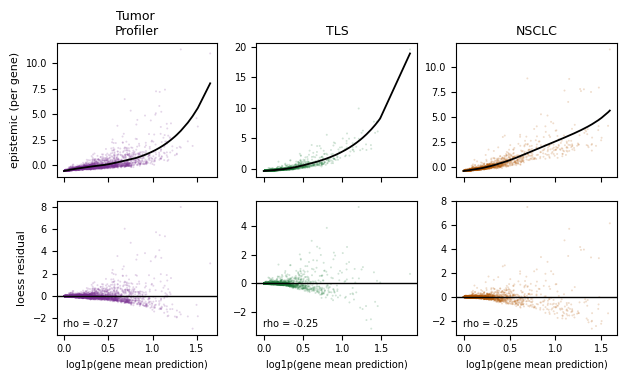

     cohort  n_genes  rho_raw_vs_expr  rho_residual_vs_expr  residual_sd
  10x_TuPro     3000            0.908                -0.269        0.479
        TLS     3000            0.964                -0.253        0.288
LUNG_CANCER     3000            0.976                -0.254        0.418

CAPTION (epistemic): Expression de-confounding of the per-gene epistemic uncertainty. Top, the per-gene uncertainty against the per-gene predicted mean expression, with the locally weighted regression (loess, span 0.5, degree 2) that defines the adjustment; each point is one gene. Bottom, the residual that is ranked to build the adjusted gene sets, with its Spearman correlation against expression annotated. A residual correlation away from zero means the adjustment has not removed the expression signal but displaced it.

wrote: fig_loess_deconfound_alea_heteroscedastic_ensemble.pdf


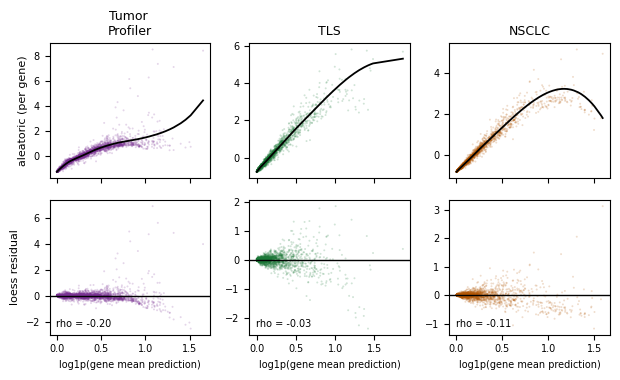

     cohort  n_genes  rho_raw_vs_expr  rho_residual_vs_expr  residual_sd
  10x_TuPro     3000            0.978                -0.196        0.366
        TLS     3000            0.988                -0.034        0.210
LUNG_CANCER     3000            0.994                -0.107        0.173

CAPTION (aleatoric): Expression de-confounding of the per-gene aleatoric uncertainty. Top, the per-gene uncertainty against the per-gene predicted mean expression, with the locally weighted regression (loess, span 0.5, degree 2) that defines the adjustment; each point is one gene. Bottom, the residual that is ranked to build the adjusted gene sets, with its Spearman correlation against expression annotated. A residual correlation away from zero means the adjustment has not removed the expression signal but displaced it.



In [12]:
# ===== FIGURE 1: the loess fit, and its residual =====
# Top row: the per-gene uncertainty against the per-gene predicted mean, with the loess curve that
# defines the de-confound. Bottom row: the residual that is actually ranked. The bottom row is the
# point of the figure: a de-confound is only clean if the residual carries no expression signal,
# and the printed Spearman says whether it does.
# The x axis is drawn on a log1p scale purely for legibility (gene mean expression is heavily
# right-skewed); the loess itself is fitted on the raw values, exactly as in the analysis above,
# and log1p is monotone so the curve is unchanged in shape order.
for AXIS, AX_LABEL in (('epi', 'epistemic'), ('alea', 'aleatoric')):
    fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.3, 3.9), sharex='col')
    axes = np.atleast_2d(axes)
    stats_rows = []
    for j, ds in enumerate(DATASETS):
        key = (ds, MODEL_FIG, METHOD_FIG)
        if key not in PG:
            continue
        df = PG[key]
        x = df['gene_mean_expr'].to_numpy()
        y = df[AXIS].to_numpy()
        ok = np.isfinite(x) & np.isfinite(y)
        lo = loess(x[ok], y[ok], span=0.5, degree=2)
        lo.fit()
        fitted = lo.outputs.fitted_values
        res = y[ok] - fitted
        xs = np.log1p(x[ok])
        o = np.argsort(xs)
        c = DS_COLORS.get(ds, 'gray')
        axes[0, j].scatter(xs, y[ok], s=2, alpha=0.20, color=c, edgecolors='none')
        axes[0, j].plot(xs[o], fitted[o], color='k', lw=1.3)
        axes[1, j].scatter(xs, res, s=2, alpha=0.20, color=c, edgecolors='none')
        axes[1, j].axhline(0, color='k', lw=1.0)
        axes[0, j].set_title(DS_SHORT.get(ds, ds), fontsize=9)
        axes[1, j].set_xlabel('log1p(gene mean prediction)', fontsize=7)
        for r in (0, 1):
            axes[r, j].tick_params(labelsize=7)
        r_raw = spearmanr(y[ok], x[ok])[0]
        r_res = spearmanr(res, x[ok])[0]
        axes[1, j].annotate(f'rho = {r_res:+.2f}', xy=(0.04, 0.06), xycoords='axes fraction',
                            fontsize=7)
        stats_rows.append(dict(cohort=ds, n_genes=int(ok.sum()), rho_raw_vs_expr=r_raw,
                               rho_residual_vs_expr=r_res, residual_sd=float(res.std())))
    axes[0, 0].set_ylabel(f'{AX_LABEL} (per gene)', fontsize=8)
    axes[1, 0].set_ylabel('loess residual', fontsize=8)
    fig.tight_layout()
    save_fig(fig, f'loess_deconfound_{AXIS}_{MODEL_FIG}_{METHOD_FIG}')
    plt.show()
    print(pd.DataFrame(stats_rows).round(3).to_string(index=False))
    print(f'\nCAPTION ({AX_LABEL}): Expression de-confounding of the per-gene {AX_LABEL}'
          ' uncertainty. Top, the per-gene uncertainty against the per-gene predicted mean'
          ' expression, with the locally weighted regression (loess, span 0.5, degree 2) that'
          ' defines the adjustment; each point is one gene. Bottom, the residual that is ranked to'
          ' build the adjusted gene sets, with its Spearman correlation against expression'
          ' annotated. A residual correlation away from zero means the adjustment has not removed'
          ' the expression signal but displaced it.\n')

wrote: fig_enrichment_raw_vs_adj_aleatoric_high_heteroscedastic_ensemble.pdf


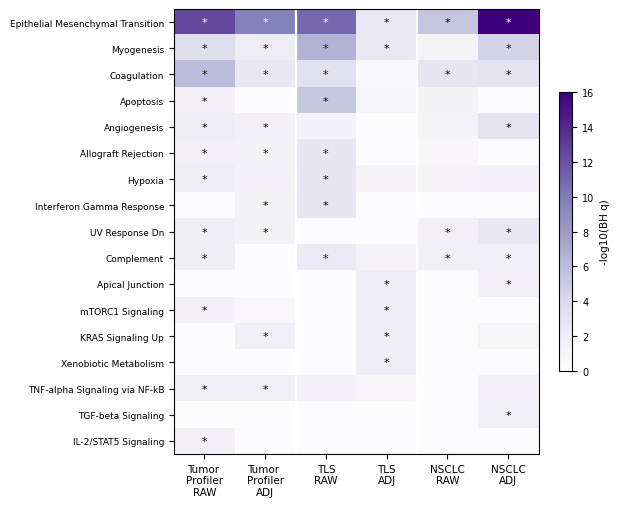

                                   Tumor \nProfiler\nRAW  Tumor \nProfiler\nADJ  TLS\nRAW  TLS\nADJ  NSCLC\nRAW  NSCLC\nADJ
Epithelial Mesenchymal Transition                  12.43                   9.63     10.92      2.44        5.38       16.00
Myogenesis                                          3.54                   2.06      6.61      2.44        1.13        4.43
Coagulation                                         5.94                   2.56      3.21      0.53        2.83        3.06
Apoptosis                                           1.56                  -0.00      5.29      0.85        1.27       -0.00
Angiogenesis                                        1.97                   1.33      1.24     -0.00        1.13        3.03
Allograft Rejection                                 1.41                   1.30      2.67     -0.00        0.76       -0.00
Hypoxia                                             1.96                   1.20      2.67      1.01        1.07        1.22
Interfer

In [13]:
# ===== FIGURE 2: enrichment with and without the expression adjustment =====
# Rows are every Hallmark term significant somewhere; columns are cohort x variant, so RAW and ADJ
# sit side by side within each cohort. A cell is blank either because the term is not significant
# or because it did not reach the top 12 returned by the ORA, which is the same cap the tables use.
LABEL_FIG, SIDE_FIG = 'aleatoric', 'high'      # edit to draw another cell of the analysis
QTHR = 0.05

cols, data = [], {}
for ds in DATASETS:
    for variant in ('RAW', 'ADJ'):
        k = (ds, MODEL_FIG, METHOD_FIG, LABEL_FIG, SIDE_FIG, variant)
        if k not in ORA_TABLES:
            continue
        col = f'{DS_SHORT.get(ds, ds)}\n{variant}'
        cols.append(col)
        t = ORA_TABLES[k].set_index('term')['q']
        data[col] = t

terms = sorted({t for s in data.values() for t in s[s < QTHR].index})
if not terms:
    print(f'no term reaches q < {QTHR} anywhere for ({LABEL_FIG}, {SIDE_FIG}). That is the result.')
else:
    M = pd.DataFrame(index=terms, columns=cols, dtype=float)
    for col, s in data.items():
        M[col] = -np.log10(s.reindex(M.index).astype(float).fillna(1.0).clip(lower=1e-16))
    M = M.loc[M.max(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(6.3, max(2.2, 0.24 * len(M) + 1.1)))
    im = ax.imshow(M.to_numpy(), aspect='auto', cmap='Purples', vmin=0)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, fontsize=7.5)
    ax.set_yticks(range(len(M)))
    ax.set_yticklabels([t.replace('_', ' ') for t in M.index], fontsize=6.5)
    for x in range(2, len(cols), 2):                 # separate the cohorts
        ax.axvline(x - 0.5, color='w', lw=1.6)
    thr = -np.log10(QTHR)
    for r in range(len(M)):                          # mark what is actually significant
        for c in range(len(cols)):
            if M.iloc[r, c] > thr:
                ax.text(c, r, '*', ha='center', va='center', fontsize=8,
                        color='w' if M.iloc[r, c] > M.to_numpy().max() * 0.6 else 'k')
    cb = fig.colorbar(im, ax=ax, fraction=0.035)
    cb.set_label('-log10(BH q)', fontsize=7.5)
    cb.ax.tick_params(labelsize=7)
    fig.tight_layout()
    save_fig(fig, f'enrichment_raw_vs_adj_{LABEL_FIG}_{SIDE_FIG}_{MODEL_FIG}_{METHOD_FIG}')
    plt.show()
    print(M.round(2).to_string())
    n_raw = int((M[[c for c in cols if c.endswith('RAW')]] > thr).sum().sum())
    n_adj = int((M[[c for c in cols if c.endswith('ADJ')]] > thr).sum().sum())
    print(f'\nsignificant cells: RAW {n_raw}, ADJ {n_adj}  (threshold -log10(q) = {thr:.2f})')
    print(f'\nCAPTION: Hallmark over-representation of the {TOP} genes with the {SIDE_FIG}est'
          f' {LABEL_FIG} uncertainty, before (RAW) and after (ADJ) removing the expression trend by'
          ' locally weighted regression, in each cohort. Color is minus the base-ten logarithm of'
          ' the Benjamini-Hochberg adjusted p value, and a star marks a term reaching q below'
          f' {QTHR}. Terms significant in no cohort and in neither variant are omitted; the gene'
          ' universe is each cohort own highly variable panel.')

wrote: fig_deconfound_residual_check.pdf


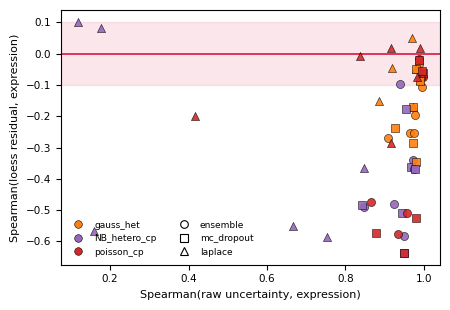

    dataset        model     method axis  ADDED_rho_raw_vs_expr  ADDED_rho_adj_vs_expr
  10x_TuPro    gauss_het   ensemble  epi                  0.908                 -0.269
  10x_TuPro    gauss_het   ensemble alea                  0.978                 -0.196
  10x_TuPro    gauss_het    laplace  epi                  0.886                 -0.153
  10x_TuPro    gauss_het    laplace alea                  0.973                 -0.169
  10x_TuPro    gauss_het mc_dropout  epi                  0.927                 -0.239
  10x_TuPro    gauss_het mc_dropout alea                  0.974                 -0.171
  10x_TuPro NB_hetero_cp   ensemble  epi                  0.847                 -0.491
  10x_TuPro NB_hetero_cp   ensemble alea                  0.973                 -0.340
  10x_TuPro NB_hetero_cp    laplace  epi                  0.118                  0.103
  10x_TuPro NB_hetero_cp    laplace alea                  0.177                  0.082
  10x_TuPro NB_hetero_cp mc_dropout  epi   

In [14]:
# ===== FIGURE 3: does the adjustment actually de-confound? =====
# One point per (cohort, model, method, axis): the Spearman of the raw per-gene uncertainty against
# expression on the x axis, and the Spearman of the loess residual against expression on the y axis.
# A clean de-confound would put every point on the horizontal zero line. This is the figure that
# justifies treating any adjusted gene set with caution.
fig, ax = plt.subplots(figsize=(4.6, 3.2))
for _, r in SENS.iterrows():
    model_key = next((k for k, v in SHORT.items() if v == r['model']), r['model'])
    ax.scatter(r['ADDED_rho_raw_vs_expr'], r['ADDED_rho_adj_vs_expr'],
               s=34, marker=METHOD_MARKERS.get(r['method'], 'o'),
               color=MODEL_COLORS.get(model_key, 'gray'),
               edgecolors='k', linewidths=0.4, alpha=0.9, zorder=3)
ax.axhline(0, color='crimson', lw=1.2, zorder=2)
ax.axhspan(-0.1, 0.1, color='crimson', alpha=0.10, zorder=1)
ax.set_xlabel('Spearman(raw uncertainty, expression)', fontsize=8)
ax.set_ylabel('Spearman(loess residual, expression)', fontsize=8)
ax.tick_params(labelsize=7.5)

from matplotlib.lines import Line2D
handles = ([Line2D([0], [0], ls='', marker='o', ms=5.5, color=MODEL_COLORS[k],
                   markeredgecolor='k', markeredgewidth=0.4, label=SHORT.get(k, k))
            for k in MODEL_COLORS if k in {m for (_, m, _) in PG}]
           + [Line2D([0], [0], ls='', marker=METHOD_MARKERS[me], ms=5.5, color='w',
                     markeredgecolor='k', markeredgewidth=0.8, label=me)
              for me in METHOD_MARKERS if me in {mm for (_, _, mm) in PG}])
ax.legend(handles=handles, fontsize=6.5, frameon=False, ncol=2, loc='lower left')
fig.tight_layout()
save_fig(fig, 'deconfound_residual_check')
plt.show()

print(SENS[['dataset', 'model', 'method', 'axis',
            'ADDED_rho_raw_vs_expr', 'ADDED_rho_adj_vs_expr']].round(3).to_string(index=False))
inside = int((SENS['ADDED_rho_adj_vs_expr'].abs() <= 0.1).sum())
print(f'\nresiduals within +/- 0.1 of zero: {inside} of {len(SENS)}'
      f'  |  median residual rho = {SENS["ADDED_rho_adj_vs_expr"].median():+.3f}')
print('\nCAPTION: Effectiveness of the expression de-confounding. Each point is one'
      ' (cohort, model, uncertainty method, axis) combination; the horizontal axis is the'
      ' correlation of the raw per-gene uncertainty with the gene mean expression and the vertical'
      ' axis that of the loess residual which is actually ranked. A perfect adjustment would place'
      ' every point on the red line; the shaded band spans plus or minus 0.1. Points falling below'
      ' the band indicate that the adjustment overshoots and tilts the ranking towards weakly'
      ' expressed genes rather than removing the expression signal.')

wrote: fig_laplace_nb_epistemic_tail.pdf


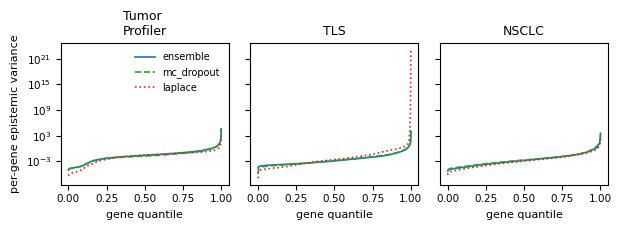

     cohort     method  n_genes  median      p99      maximum  max_over_median
  10x_TuPro   ensemble     3000  0.0257  15.4350 3.838660e+04     1.491682e+06
  10x_TuPro mc_dropout     3000  0.0167  20.3766 2.829597e+04     1.692179e+06
  10x_TuPro    laplace     3000  0.0284   2.1591 1.677829e+03     5.905643e+04
        TLS   ensemble     3000  0.0012   3.9731 1.073618e+04     9.067956e+06
        TLS mc_dropout     3000  0.0015   5.5376 3.344720e+04     2.218626e+07
        TLS    laplace     3000  0.0027 177.6293 1.174075e+23     4.274170e+25
LUNG_CANCER   ensemble     3000  0.0017  12.0653 3.725353e+03     2.226086e+06
LUNG_CANCER mc_dropout     3000  0.0020  18.6138 3.223360e+03     1.575796e+06
LUNG_CANCER    laplace     3000  0.0011   3.1364 4.596473e+02     4.010269e+05

max_over_median is the readable column: a ratio of the same order across methods is
healthy, a ratio orders of magnitude larger for one method marks a numerical blow-up.

CAPTION (supplementary): Per-gene epis

In [15]:
# ===== FIGURE 4 (diagnostic, supplement): the Laplace negative-binomial anomaly =====
# Sorted per-gene epistemic variance, on a log scale, one curve per epistemic method. The Laplace
# closed form builds the count moments as E[m] = m0 exp(sig2/2) and Var[m] = E[m]^2 (e^sig2 - 1)
# with sig2 capped at 30 (laplace_posthoc.py), so a gene whose posterior variance approaches that
# cap contributes a value orders of magnitude above the rest. Draw this before deciding whether the
# Laplace count rows may be reported at all.
MODEL_DIAG = 'negativebinomial_hetero_noanchor_cp'
have = [ds for ds in DATASETS if any(k[0] == ds and k[1] == MODEL_DIAG for k in PG)]
if not have:
    print(f'{MODEL_DIAG} not loaded; set MODELS in cell 3 to include it.')
else:
    fig, axes = plt.subplots(1, len(have), figsize=(6.3, 2.4), squeeze=False, sharey=True)
    rows = []
    for ax, ds in zip(axes[0], have):
        for method, style in (('ensemble', '-'), ('mc_dropout', '--'), ('laplace', ':')):
            key = (ds, MODEL_DIAG, method)
            if key not in PG:
                continue
            v = np.sort(PG[key]['epi_nz'].to_numpy())
            v = v[np.isfinite(v) & (v > 0)]
            ax.plot(np.linspace(0, 1, len(v)), v, style, lw=1.2, label=method,
                    color={'ensemble': '#1f77b4', 'mc_dropout': '#2ca02c', 'laplace': '#d62728'}[method])
            rows.append(dict(cohort=ds, method=method, n_genes=len(v),
                             median=float(np.median(v)), p99=float(np.percentile(v, 99)),
                             maximum=float(v.max()), max_over_median=float(v.max() / np.median(v))))
        ax.set_yscale('log')
        ax.set_xlabel('gene quantile', fontsize=8)
        ax.tick_params(labelsize=7.5)
        ax.set_title(DS_SHORT.get(ds, ds), fontsize=9)
    axes[0][0].set_ylabel('per-gene epistemic variance', fontsize=8)
    axes[0][0].legend(fontsize=7, frameon=False)
    fig.tight_layout()
    save_fig(fig, 'laplace_nb_epistemic_tail')
    plt.show()
    T = pd.DataFrame(rows)
    print(T.round(4).to_string(index=False))
    print('\nmax_over_median is the readable column: a ratio of the same order across methods is')
    print('healthy, a ratio orders of magnitude larger for one method marks a numerical blow-up.')
    print('\nCAPTION (supplementary): Per-gene epistemic variance of the negative-binomial head,'
          ' sorted and shown on a logarithmic scale, for the three epistemic methods. The Laplace'
          ' approximation produces a tail several orders of magnitude above the deep ensemble and'
          ' Monte-Carlo dropout, a consequence of the log-normal closed form in which the posterior'
          ' variance enters exponentially and is merely capped rather than bounded. The affected'
          ' rows are excluded from the analysis.')

wrote: fig_pathway_deconfound_enrichment_aleatoric_heteroscedastic_ensemble.pdf


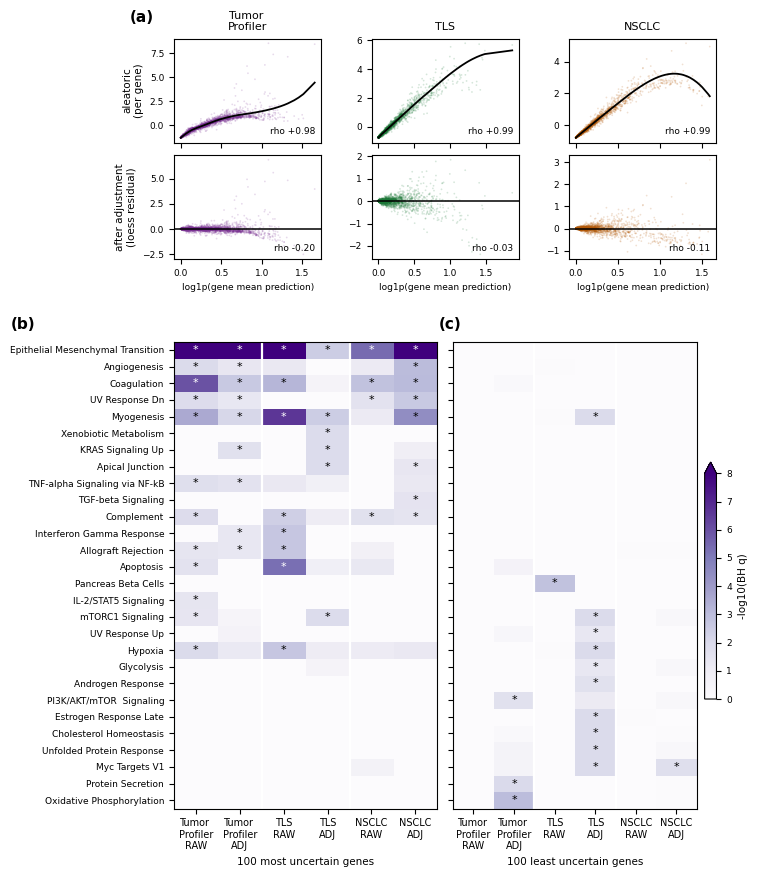


FIGURE DATA (a): the expression confound before and after the loess.
          cohort  n_genes  rho_before  rho_after  residual_sd
Tumor \nProfiler     3000       0.978     -0.196        0.366
             TLS     3000       0.988     -0.034        0.210
           NSCLC     3000       0.994     -0.107        0.173

FIGURE DATA (b, most uncertain): -log10(BH q), aleatoric axis.
                                   Tumor \nProfiler\nRAW  Tumor \nProfiler\nADJ  TLS\nRAW  TLS\nADJ  NSCLC\nRAW  NSCLC\nADJ
Epithelial Mesenchymal Transition                  12.43                   9.63     10.92      2.44        5.38       16.00
Angiogenesis                                        1.97                   1.33      1.24     -0.00        1.13        3.03
Coagulation                                         5.94                   2.56      3.21      0.53        2.83        3.06
UV Response Dn                                      1.85                   1.30     -0.00     -0.00        1.56        2.5

In [16]:
# ===== REPORT FIGURE: the expression de-confound, and what the corrected ranking recovers =====
#   a  top row    the per-gene uncertainty against expression, with the loess that defines the fit
#      bottom row the SAME data AFTER adjustment, i.e. the residual that is actually ranked
#   b  Hallmark terms of the 100 MOST uncertain genes, RAW next to ADJ
#   c  the same for the 100 LEAST uncertain genes, on the SAME rows and the same color scale
#
# The bottom row of (a) is the point of the panel. A de-confound is only clean if what is ranked
# carries no expression signal left, so the flat cloud, and the annotated correlation next to it,
# are what license reading (b) and (c) biologically.
#
# Laplace is not drawn. On this model family it agrees with the other two methods (Spearman 0.86
# to 0.96 over the 3,000 genes, section 4), so dropping it removes a redundancy, not a
# disagreement. It diverges only on the count models, which this figure does not use.
AXIS_FIG, AX_LABEL = 'alea', 'aleatoric'
QTHR = 0.05
THR = -np.log10(QTHR)
VCAP = 8.0

fig = plt.figure(figsize=(7.0, 10.0))
gs = fig.add_gridspec(2, 1, height_ratios=[1.7, 3.6], hspace=0.24)
top = gs[0].subgridspec(2, len(DATASETS), wspace=0.34, hspace=0.12)
bot = gs[1].subgridspec(1, 2, wspace=0.06)


def _letter(ax, s, dx=-0.30, dy=1.13):
    ax.annotate(f'({s})', xy=(dx, dy), xycoords='axes fraction', fontsize=11,
                fontweight='bold', va='bottom')


# ---------- a: before adjustment on top, after adjustment below ----------
# The x axis is log1p only for legibility; the loess is fitted on the raw values and log1p is
# monotone, so the curve keeps its shape and its order. Both rows share that axis, so a gene sits
# at the same horizontal position above and below.
rows_a = []
for j, ds in enumerate(DATASETS):
    ax0 = fig.add_subplot(top[0, j])
    ax1 = fig.add_subplot(top[1, j], sharex=ax0)
    key = (ds, MODEL_FIG, METHOD_FIG)
    if key not in PG:
        ax0.axis('off')
        ax1.axis('off')
        continue
    df = PG[key]
    x = df['gene_mean_expr'].to_numpy()
    y = df[AXIS_FIG].to_numpy()
    ok = np.isfinite(x) & np.isfinite(y)
    lo = loess(x[ok], y[ok], span=0.5, degree=2)
    lo.fit()
    fitted = lo.outputs.fitted_values
    res = y[ok] - fitted
    xs = np.log1p(x[ok])
    o = np.argsort(xs)
    c = DS_COLORS.get(ds, 'gray')
    r_raw = spearmanr(y[ok], x[ok])[0]
    r_res = spearmanr(res, x[ok])[0]

    ax0.scatter(xs, y[ok], s=1.6, alpha=0.18, color=c, edgecolors='none')
    ax0.plot(xs[o], fitted[o], color='k', lw=1.3)
    ax0.annotate(f'rho {r_raw:+.2f}', xy=(0.96, 0.06), xycoords='axes fraction',
                 ha='right', va='bottom', fontsize=6.5)
    ax0.set_title(DS_SHORT.get(ds, ds), fontsize=8)
    ax0.tick_params(labelsize=6.5, labelbottom=False)

    ax1.scatter(xs, res, s=1.6, alpha=0.18, color=c, edgecolors='none')
    ax1.axhline(0, color='k', lw=1.1)
    ax1.annotate(f'rho {r_res:+.2f}', xy=(0.96, 0.06), xycoords='axes fraction',
                 ha='right', va='bottom', fontsize=6.5)
    ax1.set_xlabel('log1p(gene mean prediction)', fontsize=6.5)
    ax1.tick_params(labelsize=6.5)

    if j == 0:
        ax0.set_ylabel(f'{AX_LABEL}\n(per gene)', fontsize=7.5)
        ax1.set_ylabel('after adjustment\n(loess residual)', fontsize=7.5)
        _letter(ax0, 'a')
    rows_a.append(dict(cohort=DS_SHORT.get(ds, ds), n_genes=int(ok.sum()),
                       rho_before=r_raw, rho_after=r_res, residual_sd=float(res.std())))


# ---------- b and c: the two ends of the same ranking ----------
def q_matrix(side):
    '''-log10(q) for one side of the ranking, columns = cohort x variant.'''
    cols, data = [], {}
    for ds in DATASETS:
        for variant in ('RAW', 'ADJ'):
            k = (ds, MODEL_FIG, METHOD_FIG, AX_LABEL, side, variant)
            if k not in ORA_TABLES:
                continue
            col = f'{DS_SHORT.get(ds, ds)}\n{variant}'
            cols.append(col)
            data[col] = ORA_TABLES[k].set_index('term')['q']
    return cols, data


cols_h, data_h = q_matrix('high')
cols_l, data_l = q_matrix('low')
# The rows are shared, so a term can be compared across the two ends at a glance. A term is kept
# if it is significant ANYWHERE, on either side and in either variant.
terms = sorted({t for d in (data_h, data_l) for s in d.values() for t in s[s < QTHR].index})


def build(cols, data):
    M = pd.DataFrame(index=terms, columns=cols, dtype=float)
    for col, s in data.items():
        M[col] = -np.log10(s.reindex(terms).astype(float).fillna(1.0).clip(lower=1e-16))
    return M


MH, ML = build(cols_h, data_h), build(cols_l, data_l)
# Ordered by how much a term belongs to the high end rather than the low end, taken on the ADJ
# columns only, so the high-uncertainty programmes sit at the top and the low ones at the bottom.
adj_h = MH[[c for c in cols_h if c.endswith('ADJ')]].max(axis=1)
adj_l = ML[[c for c in cols_l if c.endswith('ADJ')]].max(axis=1)
order = (adj_h - adj_l).sort_values(ascending=False).index
MH, ML = MH.loc[order], ML.loc[order]

# The color scale is shared so the two ends are comparable, but CAPPED: without the cap it is set
# by the single strongest cell and the whole of (c), an order of magnitude smaller, is drawn white.
vmax = min(VCAP, float(max(MH.to_numpy().max(), ML.to_numpy().max())))
n_sat = int((MH.to_numpy() > vmax).sum() + (ML.to_numpy() > vmax).sum())

for pos, (M, cols, letter, head) in enumerate((
        (MH, cols_h, 'b', f'{TOP} most uncertain genes'),
        (ML, cols_l, 'c', f'{TOP} least uncertain genes'))):
    ax = fig.add_subplot(bot[pos])
    im = ax.imshow(M.to_numpy(), aspect='auto', cmap='Purples', vmin=0, vmax=vmax)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, fontsize=7)
    ax.set_yticks(range(len(M)))
    ax.set_yticklabels([t.replace('_', ' ') for t in M.index] if pos == 0 else [], fontsize=6.5)
    for xx in range(2, len(cols), 2):
        ax.axvline(xx - 0.5, color='w', lw=1.6)
    for r in range(len(M)):
        for cc in range(len(cols)):
            if M.iloc[r, cc] > THR:
                ax.text(cc, r, '*', ha='center', va='center', fontsize=8,
                        color='w' if M.iloc[r, cc] > vmax * 0.6 else 'k')
    ax.set_xlabel(head, fontsize=7.5)
    _letter(ax, letter, dx=(-0.62 if pos == 0 else -0.06), dy=1.02)
    if pos == 1:
        cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03, extend='max')
        cb.set_label('-log10(BH q)', fontsize=7.5)
        cb.ax.tick_params(labelsize=6.5)

save_fig(fig, f'pathway_deconfound_enrichment_{AX_LABEL}_{MODEL_FIG}_{METHOD_FIG}')
plt.show()

# ---------- the printed twin ----------
print('\nFIGURE DATA (a): the expression confound before and after the loess.')
print(pd.DataFrame(rows_a).round(3).to_string(index=False))

for name, M, cols in (('b, most uncertain', MH, cols_h), ('c, least uncertain', ML, cols_l)):
    print(f'\nFIGURE DATA ({name}): -log10(BH q), {AX_LABEL} axis.')
    print(M.round(2).to_string())
    n_raw = int((M[[c for c in cols if c.endswith('RAW')]] > THR).sum().sum())
    n_adj = int((M[[c for c in cols if c.endswith('ADJ')]] > THR).sum().sum())
    print(f'  significant cells: RAW {n_raw}, ADJ {n_adj}   (threshold -log10(q) = {THR:.2f})')
print(f'\ncolor capped at -log10(q) = {vmax:.1f}; {n_sat} cell(s) saturate, exact values above.')

# WHY ONLY ONE CHANNEL IS DRAWN. The figure shows the aleatoric channel alone, which is only
# honest if the epistemic one selects comparable genes. That is measured rather than asserted:
# the rank correlation between the two per-gene scores, and the overlap of the two lists of TOP
# genes they each select, before and after the correction.
print(f'\nDO THE TWO CHANNELS SELECT THE SAME GENES? overlap out of {TOP}.')
rows_x = []
for ds in DATASETS:
    key = (ds, MODEL_FIG, METHOD_FIG)
    if key not in PG:
        continue
    df = PG[key]
    for variant, ce, ca in (('RAW', 'epi', 'alea'), ('ADJ', 'epi_adj', 'alea_adj')):
        ok = np.isfinite(df[ce].to_numpy()) & np.isfinite(df[ca].to_numpy())
        e, a, g = df[ce].to_numpy()[ok], df[ca].to_numpy()[ok], df['gene'].to_numpy()[ok]
        hi_e, hi_a = set(g[np.argsort(-e)[:TOP]]), set(g[np.argsort(-a)[:TOP]])
        lo_e, lo_a = set(g[np.argsort(e)[:TOP]]), set(g[np.argsort(a)[:TOP]])
        rows_x.append(dict(cohort=DS_SHORT.get(ds, ds), variant=variant, n_genes=int(ok.sum()),
                           rho_epi_alea=round(float(spearmanr(e, a)[0]), 3),
                           shared_high=len(hi_e & hi_a), shared_low=len(lo_e & lo_a)))
print(pd.DataFrame(rows_x).to_string(index=False))

print('\nNOT DRAWN, the epistemic axis, n significant and top term per cohort, side and variant:')
rows_e = []
for ds in DATASETS:
    for side in ('high', 'low'):
        for variant in ('RAW', 'ADJ'):
            k = (ds, MODEL_FIG, METHOD_FIG, 'epistemic', side, variant)
            if k not in ORA_TABLES:
                continue
            t = ORA_TABLES[k]
            rows_e.append(dict(cohort=DS_SHORT.get(ds, ds), side=side, variant=variant,
                               n_sig=int((t['q'] < QTHR).sum()), top_term=t.iloc[0]['term'],
                               top_q=round(float(t.iloc[0]['q']), 4)))
print(pd.DataFrame(rows_e).to_string(index=False))

print('\nCAPTION: What the per-gene uncertainty ranks, before and after the expression trend is'
      ' removed. (a) Per-gene aleatoric uncertainty against the per-gene mean prediction, one'
      ' point per gene, one cohort per column. Top row, the raw uncertainty with the locally'
      ' weighted regression (loess, span 0.5, degree 2) that defines the correction drawn in'
      ' black. Bottom row, the same genes after adjustment, that is the residual of that fit,'
      ' which is what the rankings below use. The annotated number is the Spearman correlation'
      f' with expression in each row. (b) Hallmark over-representation of the {TOP} genes carrying'
      f' the highest aleatoric uncertainty and (c) of the {TOP} carrying the lowest, each taken on'
      ' the raw ranking (RAW) and on the corrected one (ADJ), in each cohort. The two panels share'
      f' their rows and their color scale, capped so that both ends stay legible ({n_sat} cell(s)'
      ' saturate). Color is minus the base-ten logarithm of the Benjamini-Hochberg adjusted p'
      ' value and a star marks q below 0.05; terms significant in no column are omitted, and the'
      ' gene universe is each cohort own highly variable panel. The heteroscedastic Gaussian is'
      ' shown, with the deep ensemble as the epistemic source.')

In [17]:
# ===== EXPORT: the per-gene table, so the variance comparison runs without reloading anything ===
# Rebuilding PG means reading every test_summaries.h5ad. The comparison against the variance of
# the data needs only these few numbers per gene, so they are written once here and the
# downstream analysis reads this parquet instead.
#
# Everything is written, every (dataset, model, method) block and every column of PG, including
# the _adj residuals, so the downstream notebook never has to refit anything that was fitted here.
OUT_PG = PROJ / 'results' / '_analysis' / 'gene_variance' / 'per_gene_scores.parquet'
OUT_PG.parent.mkdir(parents=True, exist_ok=True)

frames = []
for (ds, model, method), df in PG.items():
    keep = df.copy()
    keep.insert(0, 'method', method)
    keep.insert(0, 'model', model)
    keep.insert(0, 'dataset', ds)
    frames.append(keep)
ALL_PG = pd.concat(frames, ignore_index=True)
ALL_PG.to_parquet(OUT_PG, index=False)

print(f'wrote {OUT_PG}')
print(f'  {len(ALL_PG):,} rows over '
      f'{ALL_PG.groupby(["dataset", "model", "method"]).ngroups} (dataset, model, method) blocks')
print('  columns:', list(ALL_PG.columns))
print('\nper block:')
print(ALL_PG.groupby(['dataset', 'model', 'method']).size().to_string())

wrote /cluster/work/grlab/projects/projects2026-msc-thesis-uncertainty-vst/clean_repo/results/_analysis/gene_variance/per_gene_scores.parquet
  81,000 rows over 27 (dataset, model, method) blocks
  columns: ['dataset', 'model', 'method', 'gene', 'epi', 'alea', 'total', 'epi_frac', 'epi_nz', 'alea_nz', 'gene_mean_expr', 'gene_obs_expr', 'pred_corr', 'target_var', 'epi_adj', 'epi_adjobs', 'alea_adj', 'alea_adjobs', 'total_adj', 'total_adjobs', 'epi_frac_adj', 'epi_frac_adjobs']

per block:
dataset      model                                method    
10x_TuPro    heteroscedastic                      ensemble      3000
                                                  laplace       3000
                                                  mc_dropout    3000
             negativebinomial_hetero_noanchor_cp  ensemble      3000
                                                  laplace       3000
                                                  mc_dropout    3000
             poisson_cp         